In [58]:
import requests
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns

In [59]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive?latitude=-7.2575&longitude=112.7521&start_date=2025-01-01&end_date=2025-06-30&hourly=temperature_2m,relative_humidity_2m,rain,wind_speed_10m,surface_pressure"

res = requests.get(url)

if res.status_code == 200:
    data = res.json()
    if 'hourly' in data:
        df_weather = pd.DataFrame(data['hourly'])
        df_weather.to_csv("weather_data_raw.csv", index=False)
        print(f"Data berhasil diambil! Total baris: {len(df_weather)}")
    else:
        print("API mengembalikan pesan error:", data)
else:
    print(f"Gagal terhubung ke API. Status HTTP: {res.status_code}")

Gagal terhubung ke API. Status HTTP: 500


In [60]:
df = pd.read_csv("weather_data_raw.csv")
print("--- DATASET ---")
print(df_weather.head())
print("--- SHAPE DATASET ---")
print(df.shape)
print("\n--- STATISTIK DESKRIPTIF ---")
print(df.describe())
print("\n--- INFO DATASET ---")
print(df.dtypes)
print(df.info())

--- DATASET ---
               time  temperature_2m  relative_humidity_2m  rain  \
0  2025-01-01T00:00            25.4                    92   0.2   
1  2025-01-01T01:00            27.2                    84   0.1   
2  2025-01-01T02:00            27.7                    83   0.2   
3  2025-01-01T03:00            27.9                    84   0.4   
4  2025-01-01T04:00            27.9                    85   1.7   

   wind_speed_10m  surface_pressure  
0             4.1            1008.6  
1             5.9            1008.4  
2             6.0            1008.5  
3             5.2            1008.3  
4             3.5            1007.9  
--- SHAPE DATASET ---
(4344, 6)

--- STATISTIK DESKRIPTIF ---
       temperature_2m  relative_humidity_2m         rain  wind_speed_10m  \
count     4344.000000           4344.000000  4344.000000     4344.000000   
mean        27.473043             81.495856     0.319268        6.717173   
std          2.060108             10.930378     1.060537       

In [61]:
modus = df.select_dtypes(include=['number']).mode().iloc[0]
print("--- MODUS TIAP ATRIBUT NUMERIK ---")
print(modus)

--- MODUS TIAP ATRIBUT NUMERIK ---
temperature_2m            25.8
relative_humidity_2m      88.0
rain                       0.0
wind_speed_10m             2.7
surface_pressure        1007.9
Name: 0, dtype: float64


Terdapat 6 fitur:
| Nama Fitur | Satuan Ukur | Tipe Data & Atribut | Kegunaan & Fungsi Analisis |
| :--- | :--- | :--- | :--- |
| `time` | ISO 8601 (`YYYY-MM-DDTHH:MM`) | Numerik Diskrit | Penanda waktu pencatatan data untuk analisis tren deret waktu (*time-series*). |
| `temperature_2m` | Derajat Celsius (°C) | Numerik Kontinu | Mengukur suhu udara pada ketinggian 2 meter di atas tanah untuk analisis kondisi termal. |
| `relative_humidity_2m` | Persentase (%) | Numerik Kontinu | Mengukur tingkat kejenuhan uap air di udara; digunakan untuk menguji korelasi terhadap suhu. |
| `rain` | Milimeter (mm) | Numerik Kontinu | Mengukur volume presipitasi cair per jam untuk mengidentifikasi intensitas hujan. |
| `wind_speed_10m` | Kilometer per jam (km/jam) | Numerik Kontinu | Mengukur kecepatan pergerakan angin pada ketinggian 10 meter untuk deteksi sirkulasi udara dan pencilan. |
| `surface_pressure` | Hectopascal (hPa) | Numerik Kontinu | Mengukur tekanan atmosfer di permukaan tanah untuk memantau kestabilan massa udara. |

In [62]:
cat_cols = df.columns
for col in cat_cols:
    print(f"\nFrekuensi {col}:")
    print(df[col].value_counts())


Frekuensi time:
time
2025-06-30T23:00    1
2025-01-01T00:00    1
2025-01-01T01:00    1
2025-01-01T02:00    1
2025-01-01T03:00    1
                   ..
2025-01-01T12:00    1
2025-01-01T11:00    1
2025-01-01T10:00    1
2025-01-01T09:00    1
2025-01-01T08:00    1
Name: count, Length: 4344, dtype: int64

Frekuensi temperature_2m:
temperature_2m
25.8    96
25.4    89
25.2    88
25.6    87
26.7    87
        ..
23.6     2
32.4     2
23.4     1
23.5     1
23.3     1
Name: count, Length: 99, dtype: int64

Frekuensi relative_humidity_2m:
relative_humidity_2m
88    218
91    195
90    185
89    182
92    175
     ... 
44      2
45      2
40      2
41      2
38      1
Name: count, Length: 61, dtype: int64

Frekuensi rain:
rain
0.0     2760
0.1      604
0.2      237
0.3      107
0.4       79
        ... 
8.3        1
7.8        1
10.3       1
11.3       1
9.2        1
Name: count, Length: 84, dtype: int64

Frekuensi wind_speed_10m:
wind_speed_10m
2.7     69
5.6     69
4.5     68
3.1     63
4.0 

In [63]:
df.notna().sum()

,0
time,4344
temperature_2m,4344
relative_humidity_2m,4344
rain,4344
wind_speed_10m,4344
surface_pressure,4344


Tidak ditemukan nilai yang hilang (missing value) pada satu pun atribut. Seluruh 4344 baris terisi penuh di keenam kolom.

In [64]:
dt = df.drop(columns=["time"],axis=1)

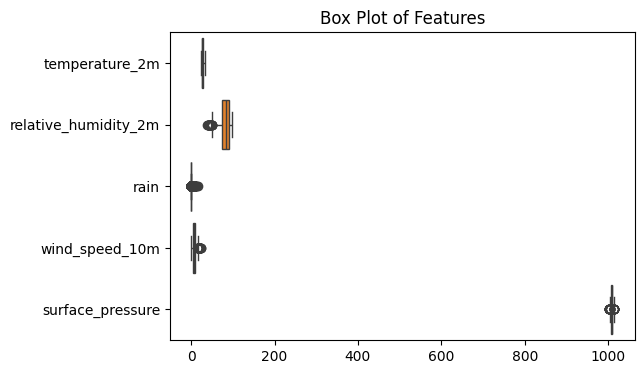


[Deteksi Outlier - Metode IQR]
- Outlier pada temperature_2m: 0 baris
- Outlier pada relative_humidity_2m: 36 baris
- Outlier pada rain: 743 baris
- Outlier pada wind_speed_10m: 73 baris
- Outlier pada surface_pressure: 24 baris


In [65]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=dt, orient='h')
plt.title('Box Plot of Features')
plt.show()
print("\n[Deteksi Outlier - Metode IQR]")
for col in dt.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"- Outlier pada {col}: {len(outliers)} baris")

Tidak ditemukan missing value pada seluruh kolom. Deteksi outlier IQR menunjukkan rain memiliki outlier terbanyak (743 dari 4344, sekitar 17%), wajar karena sebagian besar jam tidak hujan sehingga jam-jam hujan otomatis terdeteksi sebagai outlier oleh IQR meski itu kejadian nyata, bukan data error. relative_humidity_2m , wind_speed_10m , dan surface_pressure punya outlier moderat, sedangkan temperature_2m tidak punya outlier sama sekali yang mengindikasikan suhu Surabaya relatif stabil selama periode ini.

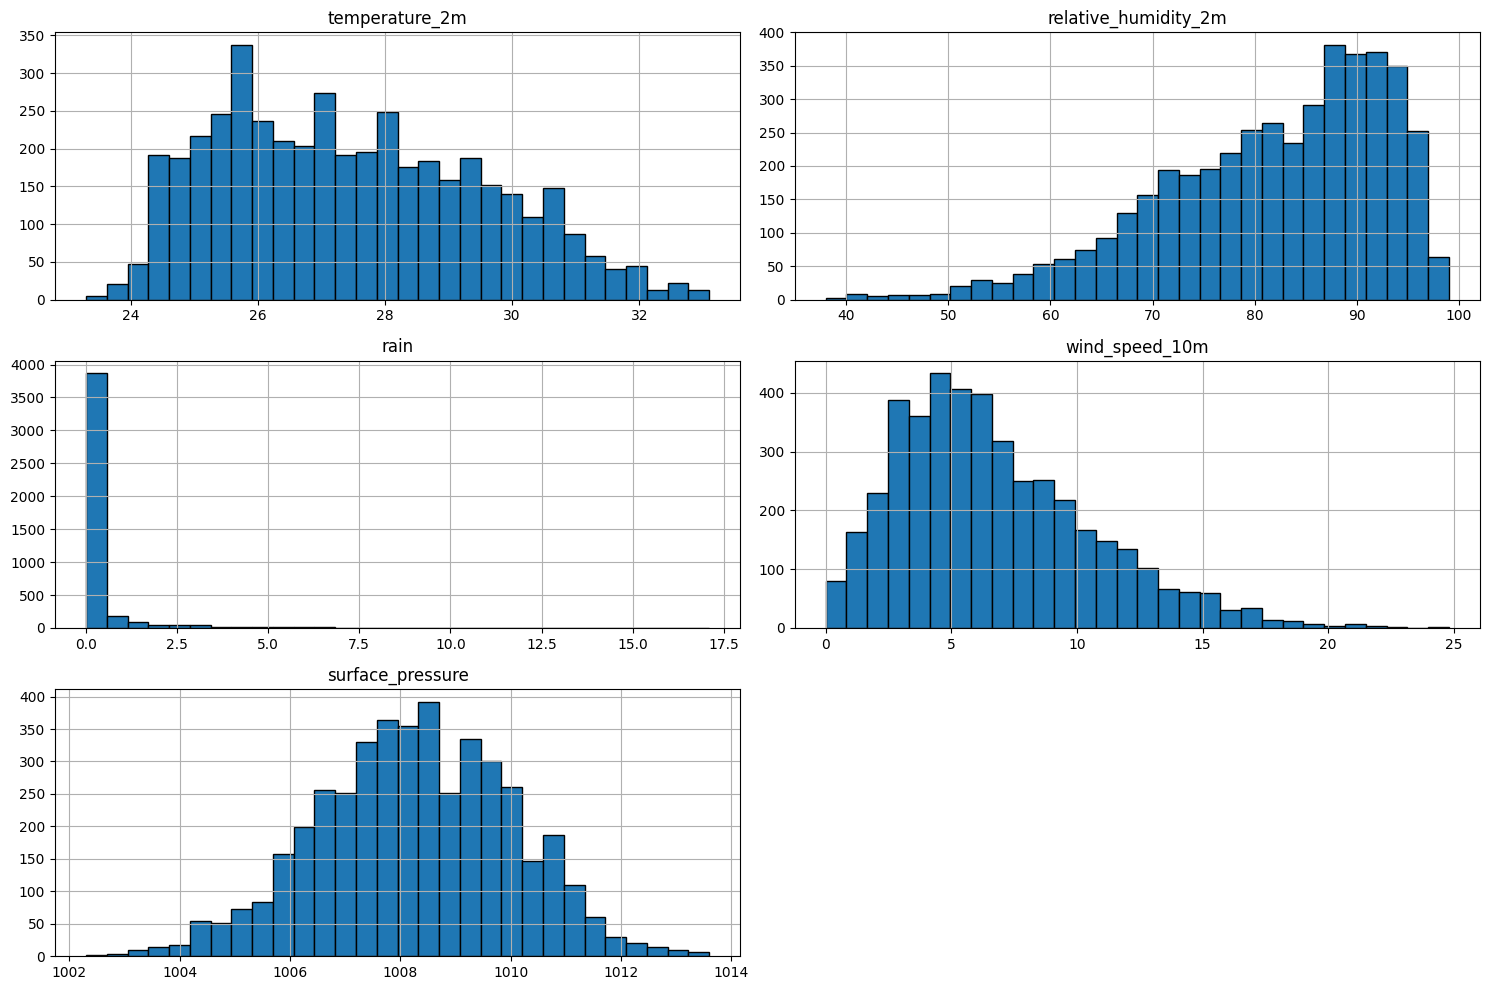

In [66]:
df.select_dtypes(include=['number']).hist(figsize=(15, 10), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

**Interpretasi Histogram (Univariat):**
- `temperature_2m` dan `surface_pressure` mendekati distribusi normal, menandakan suhu dan tekanan udara Surabaya relatif stabil selama Jan-Jun 2025.
- `relative_humidity_2m` condong ke kiri (skew negatif), mayoritas berada di rentang 80-95%, khas iklim tropis lembap.
- `rain` sangat *right-skewed* ekstrem — hampir seluruh data menumpuk di 0 mm, hanya sebagian kecil jam yang mengalami hujan deras. Ini konsisten dengan banyaknya outlier yang terdeteksi pada atribut ini.
- `wind_speed_10m` juga *right-skewed*, mayoritas kecepatan angin berada di 2-10 km/jam dengan ekor panjang ke kecepatan tinggi.

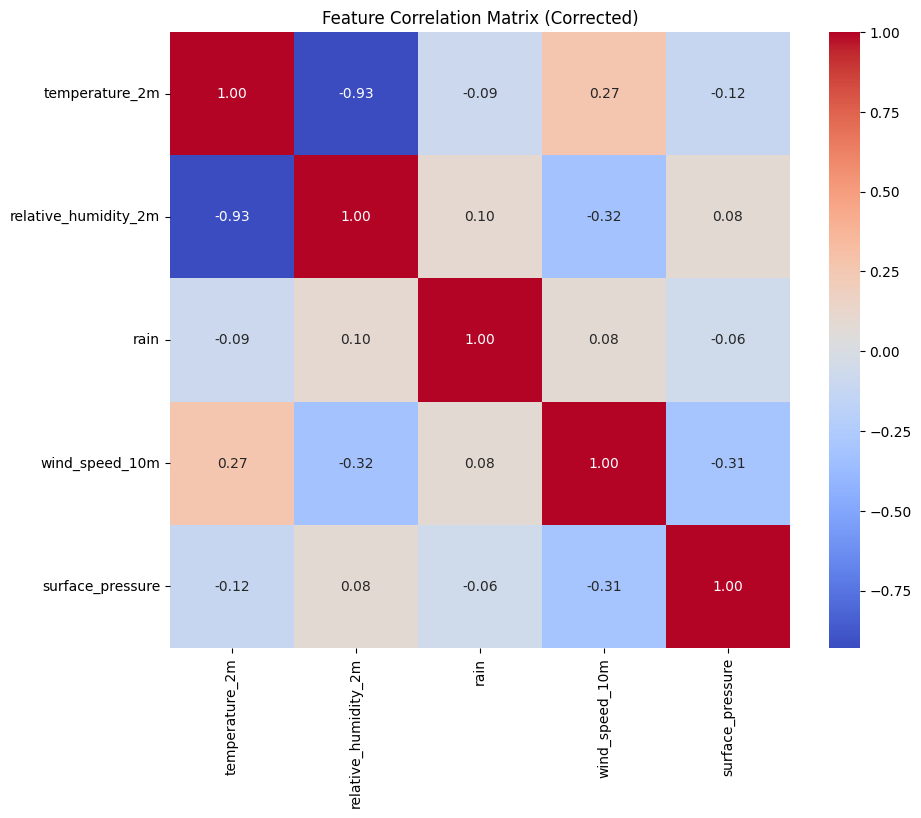

In [67]:
plt.figure(figsize=(10, 8))
sns.heatmap(dt.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Matrix (Corrected)')
plt.show()

- `temperature_2m` dan `relative_humidity_2m` bernilai negatif kuat (mendekati -1), makin panas suhu, makin rendah kelembapan relatif.
- `wind_speed_10m` dan `surface_pressure` berkorelasi negatif sedang (-0.69), serta `temperature_2m` dan `wind_speed_10m` berkorelasi positif sedang (0.56).
- `rain` relatif tidak berkorelasi kuat dengan atribut lain (|r| < 0.3 terhadap semua atribut), menandakan kejadian hujan di Surabaya pada periode ini tidak terlalu terikat pola harian suhu/kelembapan/angin.

In [68]:
cde = {"Temperatur":"temperature_2m", "Kelembapan":"relative_humidity_2m", "Hujan":"rain", "Kecepatan Angin":"wind_speed_10m", "Tekanan Udara":"surface_pressure"}

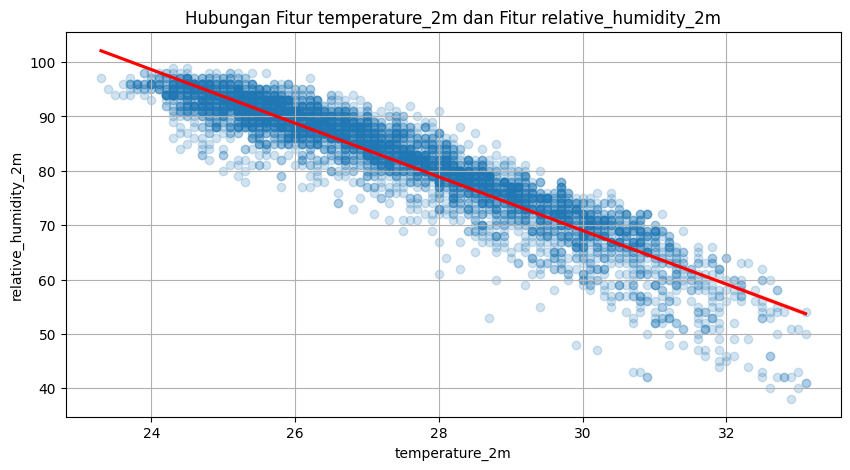

In [69]:
plt.figure(figsize=(10, 5))
# Memplot fitur_x terhadap fitur_y
x=cde['Temperatur']
y=cde['Kelembapan']
sns.regplot(data=df, x=x, y=y, scatter_kws={'alpha': 0.2},line_kws={'color': 'red'})
plt.title(f'Hubungan Fitur {x} dan Fitur {y}')
plt.xlabel(x)
plt.ylabel(y)
plt.grid(True)
plt.show()

Hubungan negatif kuat antara suhu dan kelembapan relatif, namun sebarannya cukup lebar di sekitar garis regresi

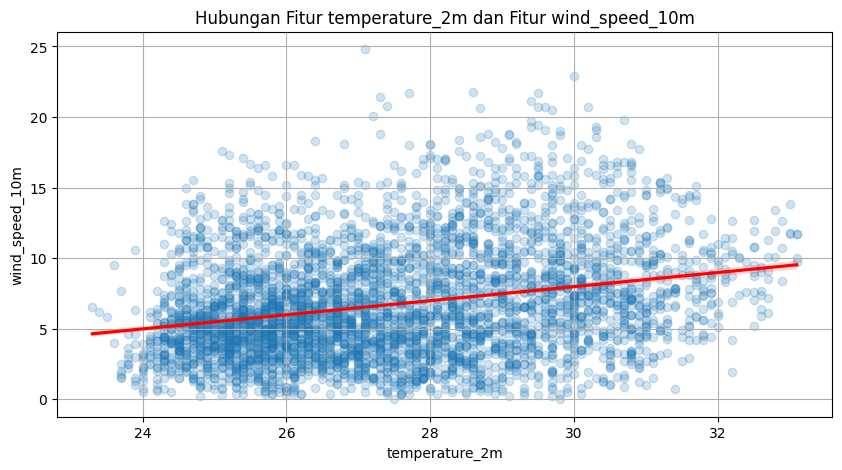

In [70]:
plt.figure(figsize=(10, 5))
# Memplot fitur_x terhadap fitur_y
x=cde['Temperatur']
y=cde['Kecepatan Angin']
sns.regplot(data=df, x=x, y=y, scatter_kws={'alpha': 0.2},line_kws={'color': 'red'})
plt.title(f'Hubungan Fitur {x} dan Fitur {y}')
plt.xlabel(x)
plt.ylabel(y)
plt.grid(True)
plt.show()

Korelasi positif sedang antara suhu dan kecepatan angin. Semakin siang/panas, aktivitas angin cenderung sedikit meningkat

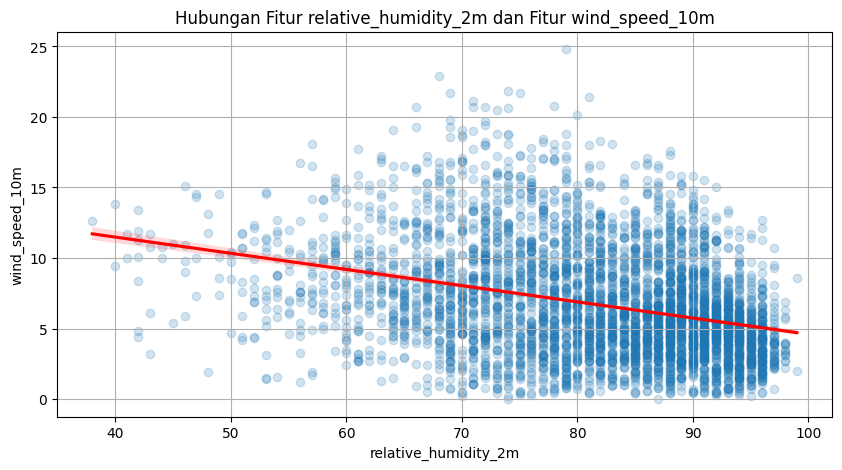

In [71]:
plt.figure(figsize=(10, 5))
# Memplot fitur_x terhadap fitur_y
x=cde['Kelembapan']
y=cde['Kecepatan Angin']
sns.regplot(data=df, x=cde['Kelembapan'], y=cde['Kecepatan Angin'], scatter_kws={'alpha': 0.2},line_kws={'color': 'red'})
plt.title(f'Hubungan Fitur {x} dan Fitur {y}')
plt.xlabel(x)
plt.ylabel(y)
plt.grid(True)
plt.show()

korelasi negatif sedang, saat kelembapan tinggi, kecepatan angin cenderung lebih rendah dibanding saat udara lebih kering

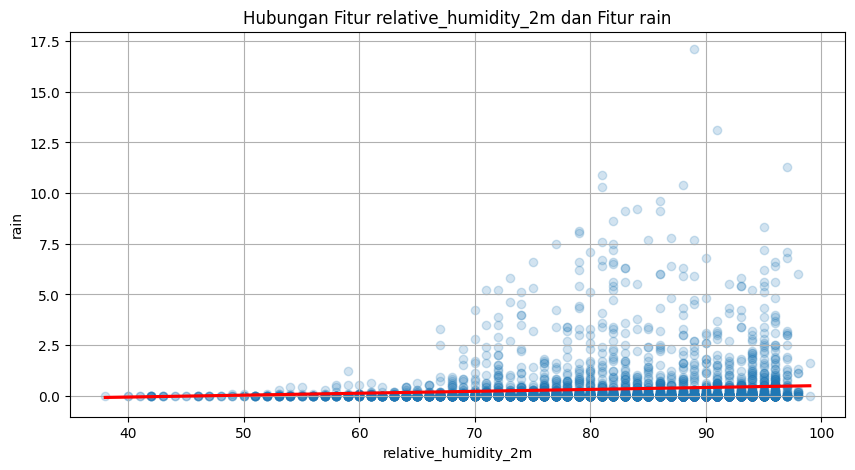

In [72]:
plt.figure(figsize=(10, 5))
# Memplot fitur_x terhadap fitur_y
x=cde['Kelembapan']
y=cde['Hujan']
sns.regplot(data=df, x=x, y=y, scatter_kws={'alpha': 0.2},line_kws={'color': 'red'})
plt.title(f'Hubungan Fitur {x} dan Fitur {y}')
plt.xlabel(x)
plt.ylabel(y)
plt.grid(True)
plt.show()

Sangat lemah dan bersebaran acak